# EDA + corruption audit — Davide

Independent EDA of the AN2DL 2026-27 challenge data (10 galaxy classes, 256×256 RGB, metric weighted F1),
done **before** looking at the teammate's results in `an2dl2627-batchsize4/`, then compared with them (§10).

**How the pieces fit**

| file | role |
|---|---|
| `eda/01_audit_davide.py` | the engine: one parallel pass over all 19,064 images (~2.5 min), detectors, matching, all figures; rebuilds `eda/outputs/davide/` |
| `eda/02_embeddings_davide.py` | CNN embeddings (torch + timm): UMAP, k-NN, linear probe, outliers → `06_embeddings/` (~30 min the first time, then cached) |
| `eda/03_test_distortions_davide.py` | measures the test hue rotation and blur → `07_test_distortions/` + augmentation parameters (~1 min) |
| **this notebook** | the story: reads the engine's outputs, recomputes the key tables and charts inline, shows the most important contact sheets, states the conclusions |
| `eda/outputs/davide/` | every figure, contact sheet and single PNG (folders `01_`…`06_`, `images/`) + CSVs |
| `eda/EDA_GUIDE_davide.md` | how to read every output file (axes, units, legends) |

Decisions taken by eye are applied by the script (`MANUAL` block) and logged in §7.

The heavy work stays in the script because its multiprocessing workers must live in an importable module (macOS *spawn*).
Set `RUN_AUDIT = True` below to regenerate the outputs from this notebook (both scripts).

**Contents** 1. Data integrity · 2. Categories · 3. Labels and classes · 4. Train corruptions (aliens, grainy copies, duplicates) ·
5. What the test looks like · 6. Train ↔ test shift · 7. Cleaning proposal · 8. CNN embeddings · 9. Test distortions measured for augmentation · 10. Conclusions for training

In [1]:
%matplotlib inline
import io, os, subprocess, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as IPImage, Markdown, display
from PIL import Image

# repo root = first parent folder that contains src/data.py (works whatever the notebook's working dir is)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'data.py').exists())
sys.path.insert(0, str(ROOT / 'src'))
from data import CLASS_NAMES, N_CLASSES  # noqa: E402

DATA = ROOT / 'data'
OUT = ROOT / 'eda' / 'outputs' / 'davide'
RUN_AUDIT = False   # True -> rerun both scripts (~2.5 min + ~1 min once embeddings are cached)


def run(script):
    res = subprocess.run([sys.executable, str(ROOT / 'eda' / script)], capture_output=True, text=True, cwd=ROOT)
    print(res.stdout.replace(str(ROOT), '.')[-700:], res.stderr.replace(str(ROOT), '.')[-600:] if res.returncode else '')
    assert res.returncode == 0


if RUN_AUDIT or not (OUT / 'csv' / 'per_image.csv').exists():
    run('01_audit_davide.py')
if RUN_AUDIT or not (OUT / '06_embeddings' / 'embedding_analysis.csv').exists():
    run('02_embeddings_davide.py')
if RUN_AUDIT or not (OUT / '07_test_distortions' / 'augmentation_params.json').exists():
    run('03_test_distortions_davide.py')

per = pd.read_csv(OUT / 'csv' / 'per_image.csv')
per['tint'] = per['tint'].fillna('')
cp = pd.read_csv(OUT / 'csv' / 'cleaning_proposal_davide.csv')
gm = pd.read_csv(OUT / 'csv' / 'grainy_matches.csv')
nd = pd.read_csv(OUT / 'csv' / 'near_duplicates.csv')
tr, te = per[per['split'] == 'train'], per[per['split'] == 'test']
clean = tr[tr['category'] == 'clean']
SHORT = {c: CLASS_NAMES[c].split('_')[0] for c in range(N_CLASSES)}
pd.set_option('display.width', 160)


def show(rel_path, width=1100):
    # embed a figure from eda/outputs/davide, downscaled to JPEG so the notebook stays small
    im = Image.open(OUT / rel_path).convert('RGB')
    im.thumbnail((width, 4 * width))
    buf = io.BytesIO(); im.save(buf, 'JPEG', quality=82)
    print(f'eda/outputs/davide/{rel_path}')
    display(IPImage(data=buf.getvalue(), format='jpeg'))


print(f'{len(tr)} train + {len(te)} test images; classes:', {c: CLASS_NAMES[c] for c in range(N_CLASSES)})

4328 train + 14736 test images; classes: {0: 'spaghetti_disturbed', 1: 'gemelli_merging', 2: 'gnocchi_round_smooth', 3: 'ravioli_in_between_smooth', 4: 'penne_cigar', 5: 'fusilli_barred_spiral', 6: 'fusilli_tight_spiral', 7: 'riccioli_loose_spiral', 8: 'linguine_edge_on_no_bulge', 9: 'lasagna_edge_on_bulge'}


## 1. Data integrity

Before any statistics: does every id in the CSVs have a file, is every file readable, and are all images the
same format? (`Image.open` only reads the PNG header, so this takes a few seconds.)

In [2]:
train_csv = pd.read_csv(DATA / 'train.csv')
test_csv = pd.read_csv(DATA / 'sample_submission.csv')
rows = []
for split, df in [('train', train_csv), ('test', test_csv)]:
    files = {f[:-4] for f in os.listdir(DATA / split) if f.endswith('.png')}
    fmt = pd.Series([(lambda im: f'{im.mode} {im.size[0]}x{im.size[1]}')(Image.open(DATA / split / f'{i}.png')) for i in df['id']]).value_counts()
    rows.append({'split': split, 'csv rows': len(df), 'files': len(files), 'missing files': len(set(df['id']) - files),
                 'extra files': len(files - set(df['id'])), 'duplicate ids': int(df['id'].duplicated().sum()),
                 'formats': dict(fmt)})
display(pd.DataFrame(rows).set_index('split'))
print('labels outside 0-9:', int((~train_csv['label'].between(0, N_CLASSES - 1)).sum()), '| NaN labels:', int(train_csv['label'].isna().sum()))
print('blank images (flat grey noise):', per.loc[per['blank'], 'id'].tolist())

,csv rows,files,missing files,extra files,duplicate ids,formats
split,,,,,,
train,4328,4328,0,0,0,{'RGB 256x256': 4328}
test,14736,14736,0,0,0,{'RGB 256x256': 14736}


labels outside 0-9: 0 | NaN labels: 0
blank images (flat grey noise): ['train_03848', 'test_13385', 'test_13646']


Everything is consistent: 4,328 train + 14,736 test PNGs, all RGB 256×256, no missing or extra files, labels valid.
Three images are blank (pure grey noise, `gray_std < 4`) and one train image is partly broken (§4.4).

## 2. Categories

Every image gets **one** category. The detectors are simple image statistics with thresholds (all in the `CONFIG`
block of the script); each detector was checked by eye on the contact sheets.

| category | split | what it is | how it is detected |
|---|---|---|---|
| `clean` | both | ordinary galaxy | none of the flags below |
| `alien` | train | "Area 51" intruder: an alien face pasted on the galaxy | largest pale-skin blob > 6% of the image |
| `grainy` | train | brightened grey sky + strong colour noise; degraded **copies** of clean train images with swapped labels (§4.2) | colour noise in the sky ring > 24, or (sky > 52 and luminance noise > 10) |
| `wrong_label_dup` | train | same galaxy as another train image but with a wrong label (decided by eye) | near-duplicate search + manual decision |
| `blank` | both | flat grey noise | pixel std < 4 |
| `broken` | train | missing-data block (dark, flat area) + artifact | > 5% of the 16×16 blocks dark and flat (rule from the teammate's EDA; not used on test, where blurred skies are flat too) |
| `tinted` | test | purple/pink or green/cyan colour cast | galaxy-core colour outside the 1–99% range of clean train |
| `smooth` | test | blurred (smoother than 99% of clean train) | luminance noise < 1st percentile of clean train |
| `grainy_like`, `alien_candidate` | test | look-alikes above the train thresholds — ordinary galaxies, **not** the train corruptions | same detectors |

Precedence when several flags fire: train `blank > broken > alien > wrong_label_dup > grainy > clean`;
test `blank > tinted > smooth > grainy_like > alien_candidate > clean`.

In [3]:
order = ['clean', 'grainy', 'alien', 'wrong_label_dup', 'broken', 'blank', 'tinted', 'smooth', 'grainy_like', 'alien_candidate']
cat = pd.crosstab(per['category'], per['split']).reindex(order).fillna(0).astype(int)[['train', 'test']]
cat['train %'] = (cat['train'] / len(tr) * 100).round(1)
cat['test %'] = (cat['test'] / len(te) * 100).round(1)
display(cat)
print('test flags before precedence (can overlap):', {f: int(te[f].astype(bool).sum()) for f in ['tint', 'smooth', 'grainy', 'alien', 'blank']})

split,train,test,train %,test %
category,,,,
clean,2995,8861,69.2,60.1
grainy,996,0,23.0,0.0
alien,332,0,7.7,0.0
wrong_label_dup,3,0,0.1,0.0
broken,1,0,0.0,0.0
blank,1,2,0.0,0.0
tinted,0,3320,0.0,22.5
smooth,0,2152,0.0,14.6
grainy_like,0,397,0.0,2.7


test flags before precedence (can overlap): {'tint': 3320, 'smooth': 2502, 'grainy': 448, 'alien': 6, 'blank': 2}


**Train and test are corrupted in different ways.** About 31% of train is corrupted (grainy 23%, aliens 7.7%), and none of it
appears in test. Over a third of test (37%) is tinted or blurred, and neither appears in train.

## 3. Labels and classes

Class counts three ways: raw, without aliens, and **clean** (no aliens, grainy, wrong-label, broken or blank images, which is what we train on).

,name,raw,no_alien,clean,clean %
label,,,,,
0,spaghetti_disturbed,213,183,182,6.1
1,gemelli_merging,345,313,313,10.5
2,gnocchi_round_smooth,744,706,446,14.9
3,ravioli_in_between_smooth,685,645,343,11.5
4,penne_cigar,83,56,56,1.9
5,fusilli_barred_spiral,584,549,346,11.6
6,fusilli_tight_spiral,565,541,309,10.3
7,riccioli_loose_spiral,477,445,444,14.8
8,linguine_edge_on_no_bulge,276,241,239,8.0


imbalance max/min: raw 9.0x, clean 8.0x


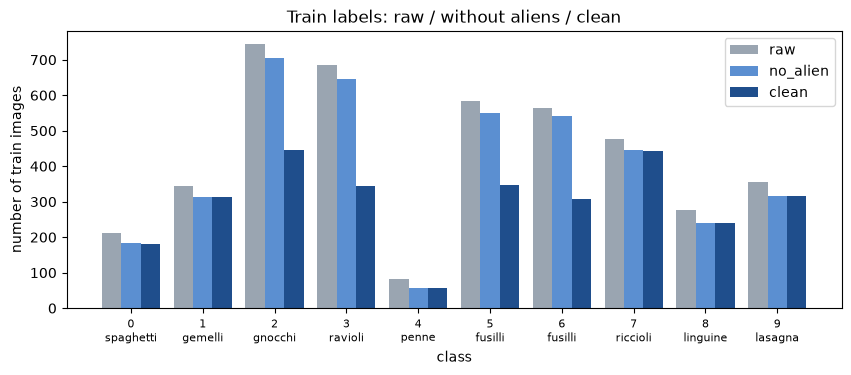

In [4]:
counts = pd.DataFrame({'raw': tr['label'].value_counts(),
                       'no_alien': tr.loc[~tr['alien'], 'label'].value_counts(),
                       'clean': clean['label'].value_counts()}).reindex(range(N_CLASSES)).fillna(0).astype(int)
counts.insert(0, 'name', [CLASS_NAMES[c] for c in counts.index])
counts['clean %'] = (counts['clean'] / counts['clean'].sum() * 100).round(1)
counts.index.name = 'label'
display(counts)
print(f"imbalance max/min: raw {counts['raw'].max() / counts['raw'].min():.1f}x, clean {counts['clean'].max() / counts['clean'].min():.1f}x")

fig, ax = plt.subplots(figsize=(10, 3.6))
for k, (col, color) in enumerate([('raw', '#9aa5b1'), ('no_alien', '#5b8fd1'), ('clean', '#1f4e8c')]):
    ax.bar(np.arange(N_CLASSES) + (k - 1) * 0.27, counts[col], 0.27, label=col, color=color)
ax.set_xticks(range(N_CLASSES)); ax.set_xticklabels([f'{c}\n{SHORT[c]}' for c in range(N_CLASSES)], fontsize=8)
ax.set_xlabel('class'); ax.set_ylabel('number of train images'); ax.legend(); ax.set_title('Train labels: raw / without aliens / clean')
plt.show()

- Class **4 (penne, cigar-shaped) is the rare class**: 56 clean images, 8× fewer than the largest classes.
- Removing the grainy copies only touches classes 2, 3, 5, 6, which stay large.

Twelve random clean images per class (one row per class, 0 at the top). The classes are visually coherent:
2 = small round blob, 3 = slightly elongated smooth, 4 = thin cigar, 5/6 = large spirals (barred / tight arms),
7 = loose spirals, 8/9 = edge-on discs (9 with a central bulge), 1 = merging pairs, 0 = disturbed/irregular.

eda/outputs/davide/01_overview/class_overview_clean.png


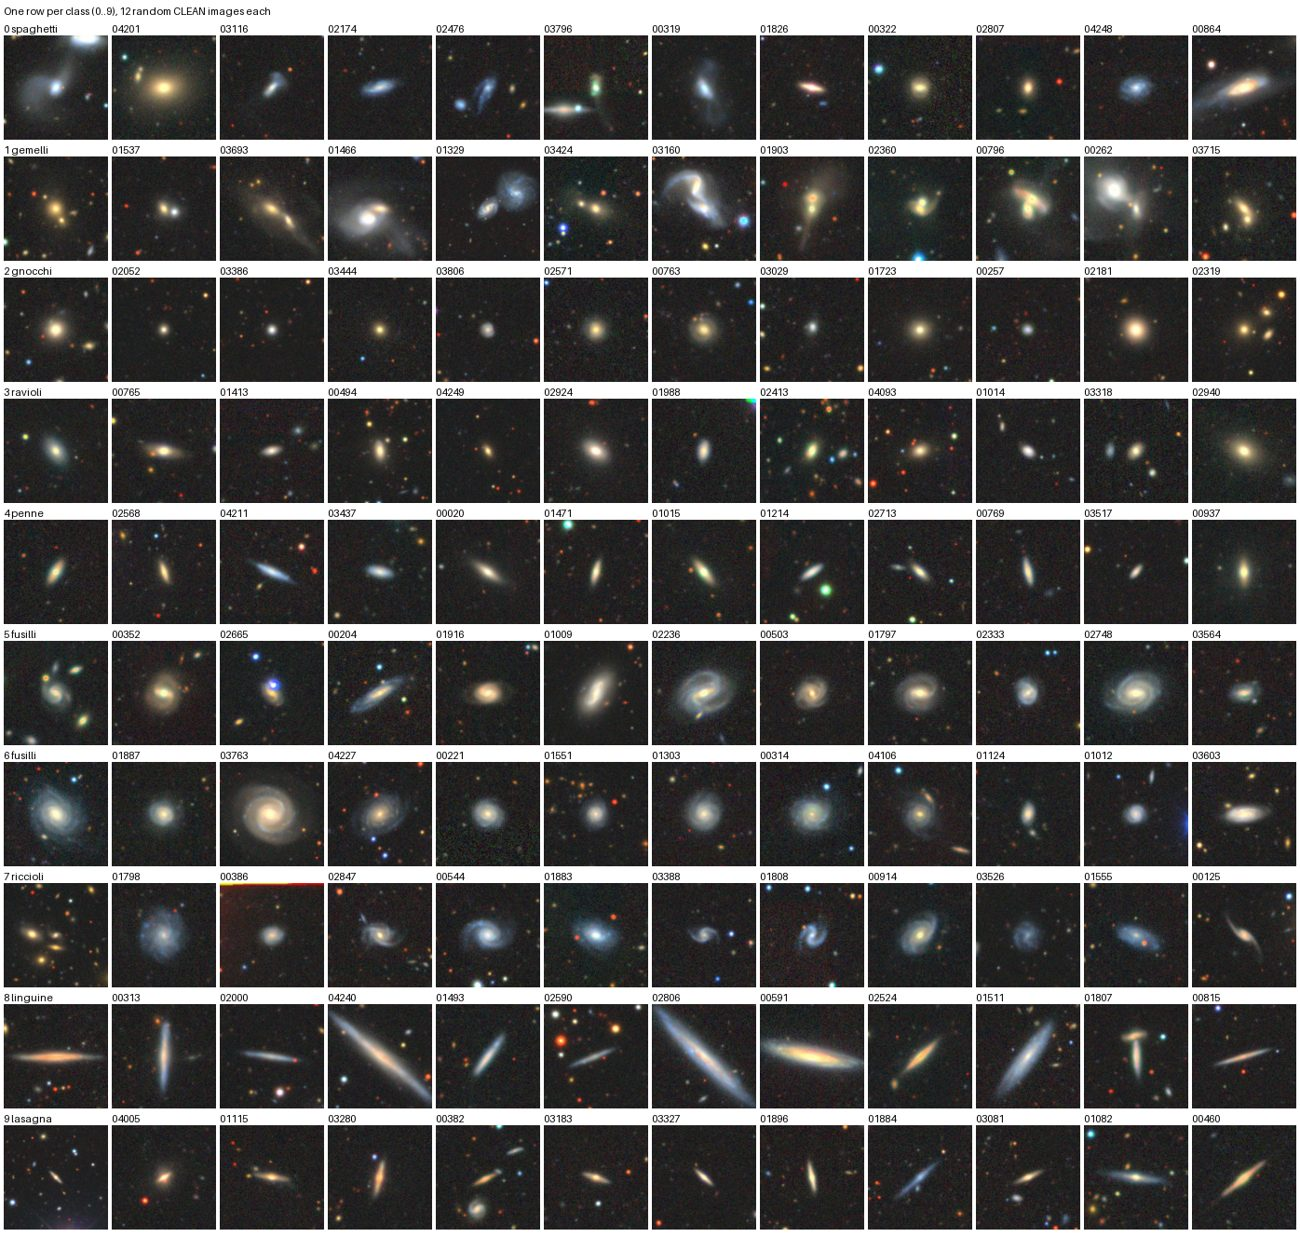

In [5]:
show('01_overview/class_overview_clean.png', width=1300)

eda/outputs/davide/01_overview/stats_by_class_clean.png


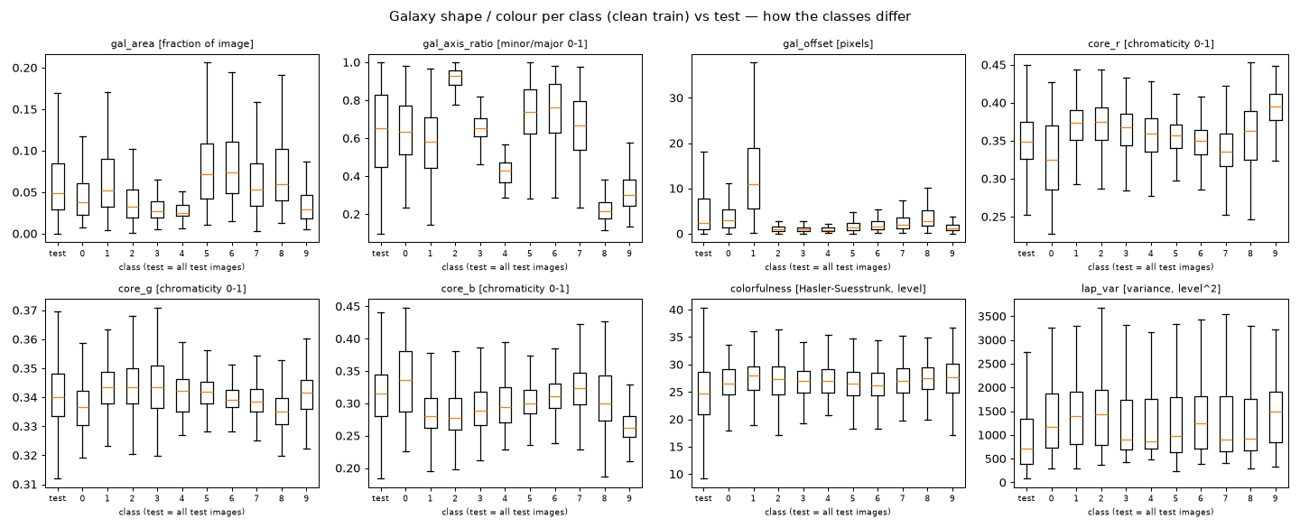

**Median per class (clean train)** — the numbers behind the boxplots:

,gal_area,gal_axis_ratio,gal_offset,core_r,core_g,core_b,colorfulness,lap_var
label,,,,,,,,
0,0.038,0.633,2.906,0.325,0.336,0.336,26.528,1163.286
1,0.052,0.581,10.851,0.374,0.343,0.280,27.951,1392.892
2,0.033,0.927,0.899,0.375,0.343,0.278,27.309,1436.673
3,0.027,0.654,0.948,0.367,0.343,0.289,27.024,893.808
4,0.025,0.428,0.874,0.360,0.342,0.295,27.031,860.743
5,0.071,0.737,1.358,0.357,0.342,0.300,26.440,974.221
6,0.073,0.761,1.666,0.350,0.339,0.310,26.255,1240.709
7,0.053,0.669,1.942,0.336,0.338,0.324,27.027,909.838
8,0.060,0.214,2.761,0.363,0.335,0.300,27.481,916.980


In [6]:
show('01_overview/stats_by_class_clean.png', width=1300)
shape_cols = ['gal_area', 'gal_axis_ratio', 'gal_offset', 'core_r', 'core_g', 'core_b', 'colorfulness', 'lap_var']
display(Markdown('**Median per class (clean train)** — the numbers behind the boxplots:'))
display(clean.groupby('label')[shape_cols].median().round(3))

The measured shapes confirm what the eye sees. Galaxy axis ratio (minor/major axis, 1 = round) is about 0.93 for class 2,
0.43 for class 4 and 0.21 / 0.30 for classes 8 / 9. Class 9 is smaller and redder in the core (the bulge).

The mean image and the mean FFT per class (`01_overview/mean_image_fft.png`) show only a centred blob and a smooth spectrum.
There is **no fixed overlay or periodic noise** a CNN could use as a shortcut.

Every train image of every class is in `02_class_sheets/` (47 pages, frame colour = category).
All pages were checked by eye: no alien hidden inside a grainy image, no grainy image among the aliens,
and no other visible corruption in classes 5 and 6.

## 4. Corruptions in the training set

### 4.1 Aliens ("Area 51" intruders)

An alien face is a large pale-skin blob, which galaxies do not have.
The score is the fraction of the image covered by the largest pale-skin blob.

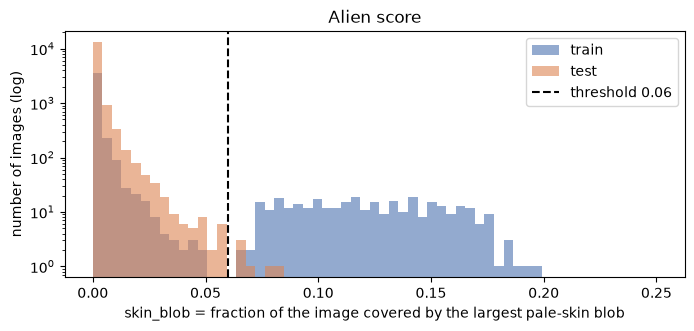

train aliens per class: {0: 30, 1: 32, 2: 38, 3: 40, 4: 27, 5: 35, 6: 24, 7: 32, 8: 35, 9: 39}
test images above the threshold (all checked: yellowish galaxies, no alien): 6


In [7]:
fig, ax = plt.subplots(figsize=(8, 3.2))
bins = np.linspace(0, max(per['skin_blob'].max(), 0.25), 60)
for s, color in [('train', '#4C72B0'), ('test', '#DD8452')]:
    ax.hist(per.loc[per['split'] == s, 'skin_blob'], bins=bins, alpha=0.6, label=s, color=color, log=True)
ax.axvline(0.06, color='k', ls='--', label='threshold 0.06')
ax.set_xlabel('skin_blob = fraction of the image covered by the largest pale-skin blob'); ax.set_ylabel('number of images (log)')
ax.legend(); ax.set_title('Alien score'); plt.show()
print('train aliens per class:', tr[tr['alien']].groupby('label').size().to_dict())
print('test images above the threshold (all checked: yellowish galaxies, no alien):', int(te['alien'].sum()))

eda/outputs/davide/03_corruptions/aliens/aliens_lowest_score.png


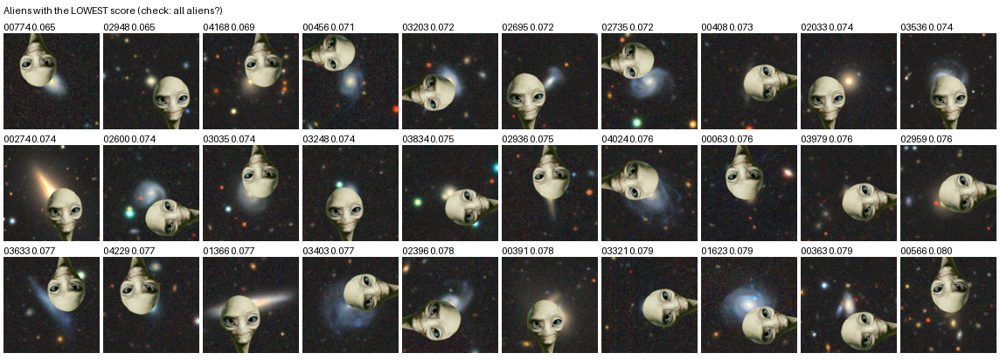

In [8]:
show('03_corruptions/aliens/aliens_lowest_score.png', width=1000)

The weakest detections above are still all aliens, and the highest-scoring non-aliens (`non_aliens_highest_score.png`) are all galaxies.
The 332 aliens are spread evenly across classes (24–40 per class) and are **train-only**, so we drop them.
One detection was wrong: `train_01971` (score 0.09) is a ring spiral whose yellow halo looks like skin. It was found by the teammate's EDA and is now excluded by hand.

### 4.2 Grainy images = degraded copies with swapped labels (most important finding)

996 train images have a brightened grey sky and strong colour noise. They appear **only in classes 2, 3, 5, 6**.
The scatter shows the two detection rules: high colour noise, or a bright sky together with luminance noise.

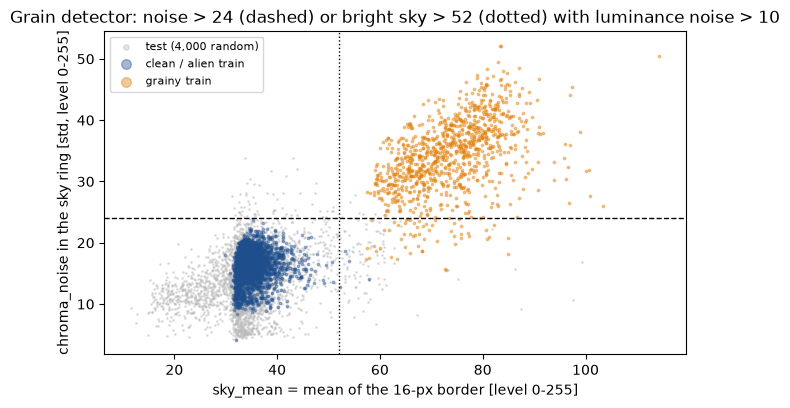

grainy per class: {2: 259, 3: 302, 5: 203, 6: 232}


In [9]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for name, d, color, s in [('test (4,000 random)', te.sample(4000, random_state=0), '#bbbbbb', 1), ('clean / alien train', tr[~tr['grainy']], '#1f4e8c', 3), ('grainy train', tr[tr['grainy']], '#e07b00', 3)]:
    ax.scatter(d['sky_mean'], d['chroma_noise'], s=s, alpha=0.4, color=color, label=name)
ax.axhline(24, color='k', ls='--', lw=1); ax.axvline(52, color='k', ls=':', lw=1)
ax.set_xlabel('sky_mean = mean of the 16-px border [level 0-255]'); ax.set_ylabel('chroma_noise in the sky ring [std, level 0-255]')
ax.set_title('Grain detector: noise > 24 (dashed) or bright sky > 52 (dotted) with luminance noise > 10'); ax.legend(markerscale=4, fontsize=8)
plt.show()
print('grainy per class:', tr[tr['grainy']].groupby('label').size().to_dict())

**Where do they come from?** Each grainy image was matched against all clean train images:
- **Candidates:** blurred 32×32 thumbnails, cosine similarity, best of the 8 rotations/flips (top 5 candidates).
- **Identity:** a *star-field* test. The point sources around the galaxy (with the galaxy masked) are a fingerprint of the sky patch.
  Two different galaxies score at most about 0.64 on calibration, so a score ≥ 0.70 means "same patch of sky".

eda/outputs/davide/03_corruptions/grainy/identity_calibration.png


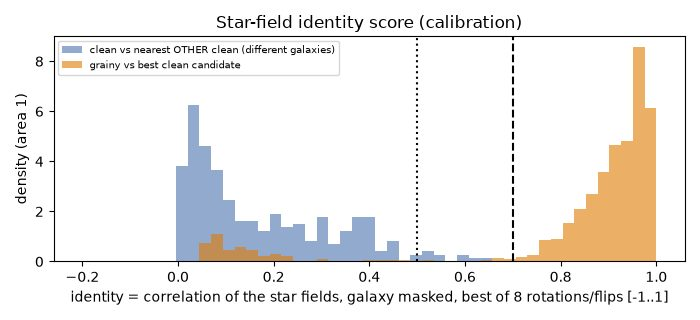

source status: {'confirmed': 890, 'none_found': 104, 'uncertain': 2} | confirmed by eye: 4
unique clean sources: 652 | copies per source: {1: 467, 2: 141, 3: 37, 4: 6, 6: 1}


**Label of the clean source (rows) vs label of its grainy copy (columns), confirmed pairs:**

grainy copy,2,3,5,6
clean source,,,,
2,0,265,0,0
3,245,0,0,0
5,0,0,0,199
6,0,0,181,0


same label in 0% of the confirmed pairs


In [10]:
show('03_corruptions/grainy/identity_calibration.png', width=800)
conf = gm[gm['source_status'] == 'confirmed']
print('source status:', gm['source_status'].value_counts().to_dict(), '| confirmed by eye:', int((gm['confirmed_by'] == 'eye').sum()))
print('unique clean sources:', conf['src_clean_id'].nunique(), '| copies per source:', conf['src_clean_id'].value_counts().value_counts().sort_index().to_dict())
display(Markdown('**Label of the clean source (rows) vs label of its grainy copy (columns), confirmed pairs:**'))
display(pd.crosstab(conf['src_clean_label'], conf['label'], rownames=['clean source'], colnames=['grainy copy']))
print(f"same label in {(conf['label'] == conf['src_clean_label']).mean():.0%} of the confirmed pairs")

eda/outputs/davide/03_corruptions/grainy/grainy_vs_source_strongest30.png


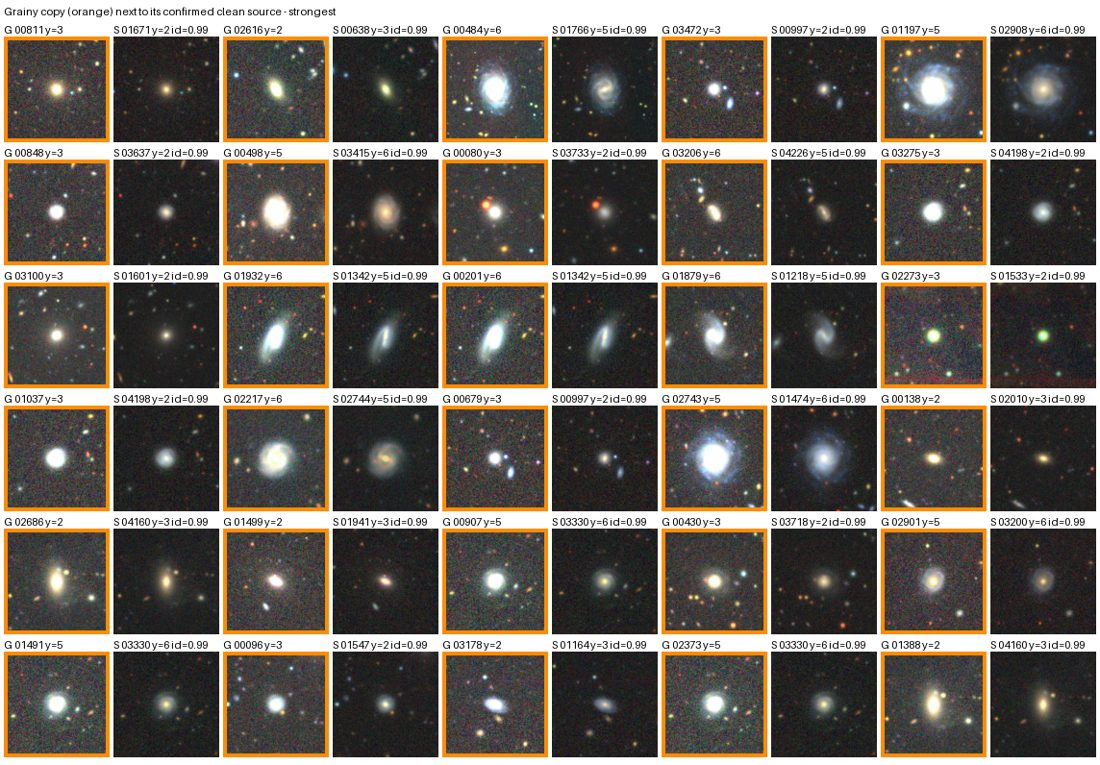

In [11]:
show('03_corruptions/grainy/grainy_vs_source_strongest30.png', width=1100)

**890 of 996 grainy images are degraded copies of 652 clean train images, and every one of them has its label swapped: 2↔3 and 5↔6.**
This is deliberate label poisoning between adjacent, plausible classes.
The pairs with the weakest identity score (`grainy_vs_source_weakest30.png`) were checked by eye: same galaxies.

Visual check: grainy images labelled 3 ("in-between") are round, so they are really class 2; grainy images labelled 2 are elongated, so they are really class 3.

Two detector errors were fixed by eye. `train_01849` (class 0) is not grainy: its bright spiral halo looked like noise. `train_00851` is grainy:
the galaxy fills the sky ring, so the detector missed it. It is the same galaxy as grainy `train_01368` / `train_01861`.

The other 106 have no confirmed source: 104 have no candidate above 0.5 and 2 are uncertain (labels 2: 14, 3: 37, 5: 22, 6: 33).
They are the same corruption in the same four classes, so their labels are probably swapped too.
Only 4 grainy images have a confident match in the test, so the corruption does not come from there.

An earlier version of this EDA matched on thumbnail similarity only. That also pairs look-alike galaxies (cosine up to 0.99), which is why the star-field test was added.

**Decision: drop all 996.** The confirmed copies add nothing beyond the clean originals we keep. Checking the other 106 by eye on degraded
images would add our own label noise. The test does not contain this corruption.

### 4.3 Duplicates

There are no exact duplicates. Near duplicates were found with a 16×16 difference hash (best of the 8 rotations/flips),
confirmed by the mean pixel difference.

In [12]:
print('near-duplicate pairs:', len(nd), '| by split:', nd['pair_type'].value_counts().to_dict())
print('by category:', (nd['cat_a'] + '-' + nd['cat_b']).value_counts().to_dict())
conf_pairs = nd[nd['label_conflict']].copy()
cat_of = per.set_index('id')['category']
conf_pairs['dropped (wrong label, by eye)'] = [a if cat_of[a] == 'wrong_label_dup' else b for a, b in zip(conf_pairs['id_a'], conf_pairs['id_b'])]
display(Markdown('**Train pairs with different labels** (same galaxy, so one label is wrong):'))
display(conf_pairs[['id_a', 'label_a', 'id_b', 'label_b', 'mad_64_min_d4', 'dropped (wrong label, by eye)']])

near-duplicate pairs: 151 | by split: {'train-train': 146, 'train-test': 3, 'test-test': 2}
by category: {'grainy-grainy': 143, 'clean-clean': 4, 'wrong_label_dup-clean': 2, 'clean-wrong_label_dup': 1, 'clean-smooth': 1}


**Train pairs with different labels** (same galaxy, so one label is wrong):

,id_a,label_a,id_b,label_b,mad_64_min_d4,"dropped (wrong label, by eye)"
1,train_00713,2,train_00854,0,0.397,train_00854
4,train_00284,7,train_01821,9,0.403,train_00284
6,train_00944,2,train_02152,6,0.413,train_00944


eda/outputs/davide/03_corruptions/duplicates/near_dups_label_conflict.png


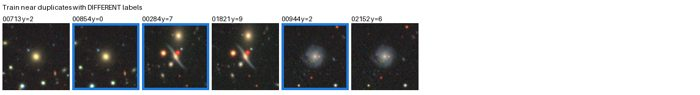

In [13]:
show('03_corruptions/duplicates/near_dups_label_conflict.png', width=700)

The 3 label conflicts were resolved by eye: the copy whose label does not match the image is dropped.

| keep | drop | why |
|---|---|---|
| `train_00713` y=2 | `train_00854` y=0 | small round yellow dot = class 2; class 0 is elliptical, blue, disturbed |
| `train_01821` y=9 | `train_00284` y=7 | edge-on with a bulge |
| `train_02152` y=6 | `train_00944` y=2 | clear spiral structure |

We are not astronomers, so the kept label may still be noisy, but the dropped copy is certainly inconsistent with it.
The 3 train↔test pairs give a free hint for those test predictions. In cross-validation, near duplicates must stay in the same fold
(column `dup_group` of the cleaning proposal, §7).

### 4.4 Broken images and straight-line artifacts

Two checks were added after comparing with the teammate's EDA:
- **Broken images**: share of 16×16 blocks that are dark and flat (missing data). Real sky always has some noise (block std ≈ 8).
- **Straight-line artifacts** (satellite trails, coloured rows/columns): `line_score` = largest jump of a row or column mean
  with respect to its neighbours, in levels 0–255.

train dark_flat > 0.05: [['train_02179', 8, 'broken', 0.144], ['train_03848', 8, 'blank', 1.0]]
test dark_flat > 0.05 (rule NOT applied to test): 639 images, of which smooth: 579


split,test,train
line_score > 25,,
clean,6,2
grainy,0,17
grainy_like,2,0
tinted,4,0


eda/outputs/davide/03_corruptions/lines/lines_top15_train_test.png


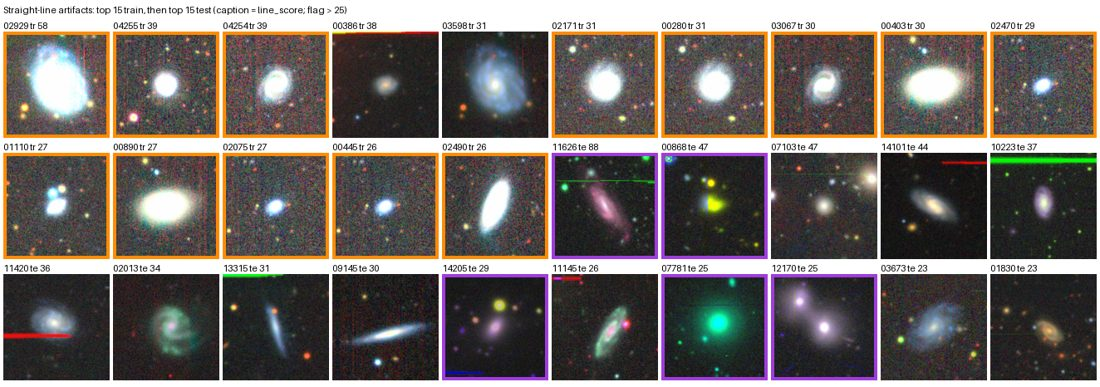

In [14]:
print('train dark_flat > 0.05:', per.loc[(per['split'] == 'train') & (per['dark_flat'] > 0.05), ['id', 'label', 'category', 'dark_flat']].round(3).values.tolist())
print('test dark_flat > 0.05 (rule NOT applied to test):', int(((per['split'] == 'test') & (per['dark_flat'] > 0.05)).sum()),
      'images, of which smooth:', int(((per['split'] == 'test') & (per['dark_flat'] > 0.05) & (per['category'] == 'smooth')).sum()))
display(pd.crosstab(per['category'], per['split'], values=per['line'], aggfunc='sum').fillna(0).astype(int).rename_axis('line_score > 25').loc[lambda d: d.sum(axis=1) > 0])
show('03_corruptions/lines/lines_top15_train_test.png', width=1100)

- `train_02179` (class 8) is broken: a rectangle of missing data with a large red artifact. It is dropped (`broken`).
- The dark-flat rule does not transfer to the test: blurred test skies look flat, so it fires on hundreds of blurred images.
  Partly broken test images, if any, would need a different rule.
- **Straight lines appear in both train and test** (a handful of clean images in each split, and many grainy images, whose amplified noise makes thin lines stand out).
  They are real observational artifacts, not a train-only corruption, so they are kept. A random-line augmentation is possible but low priority.

## 5. What the test set looks like

The test was never seen in training, so its distortions decide the augmentations.
The galaxy-core colour (chromaticity = share of R, G, B in the brightest 20% of the centre) separates the tints.

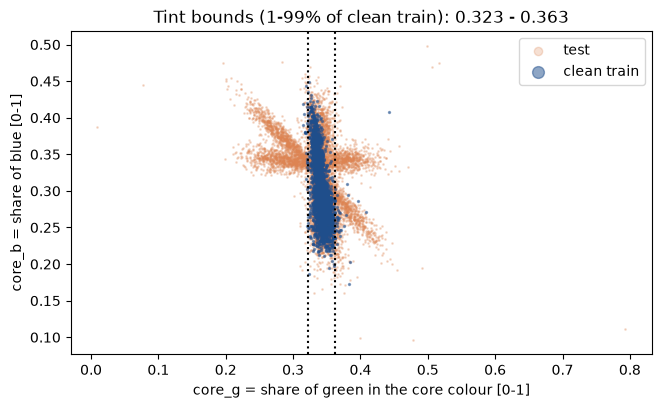

test tint: {'none': 11416, 'purple': 1959, 'green': 1361} -> 22.5% of test tinted


In [15]:
lo, hi = np.quantile(clean['core_g'], [0.01, 0.99])
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.scatter(te['core_g'], te['core_b'], s=1, alpha=0.25, color='#DD8452', label='test')
ax.scatter(clean['core_g'], clean['core_b'], s=2, alpha=0.5, color='#1f4e8c', label='clean train')
ax.axvline(lo, color='k', ls=':'); ax.axvline(hi, color='k', ls=':')
ax.set_xlabel('core_g = share of green in the core colour [0-1]'); ax.set_ylabel('core_b = share of blue [0-1]')
ax.set_title(f'Tint bounds (1-99% of clean train): {lo:.3f} - {hi:.3f}'); ax.legend(markerscale=6); plt.show()
print('test tint:', te['tint'].replace('', 'none').value_counts().to_dict(), f"-> {(te['tint'] != '').mean():.1%} of test tinted")

eda/outputs/davide/04_test/test_tinted_purple_median30.png


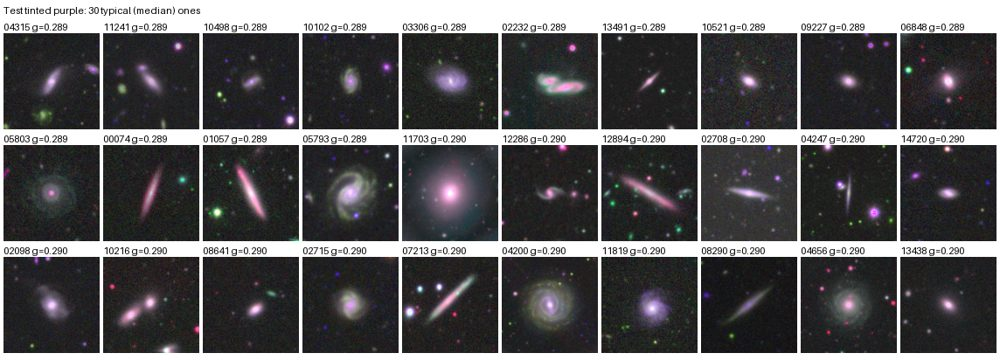

eda/outputs/davide/04_test/test_tinted_green_median30.png


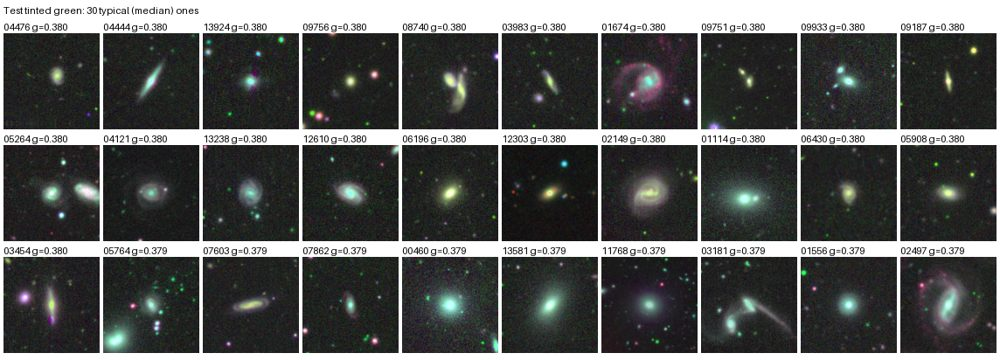

In [16]:
show('04_test/test_tinted_purple_median30.png', width=1000)
show('04_test/test_tinted_green_median30.png', width=1000)

**22.5% of the test galaxies have a purple/pink or green/cyan colour cast** that never appears in train
(the "bizarre colour distortions" announced by the organisers). The model must not rely on exact colours.
This detector only sees purple and green casts: §9 shows that the cast is a hue rotation and that at least 35% of the test is affected.

The second test distortion is **blur**: 2,502 test images are smoother than 99% of clean train.

eda/outputs/davide/04_test/test_smooth_most60.png


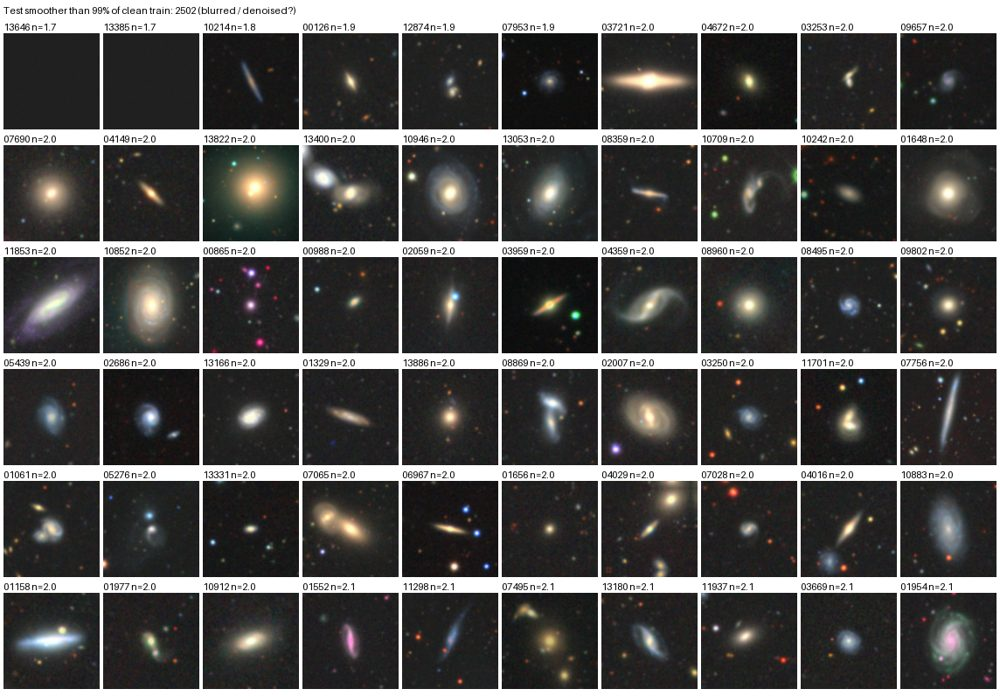

eda/outputs/davide/04_test/clean_train_smoothest30.png


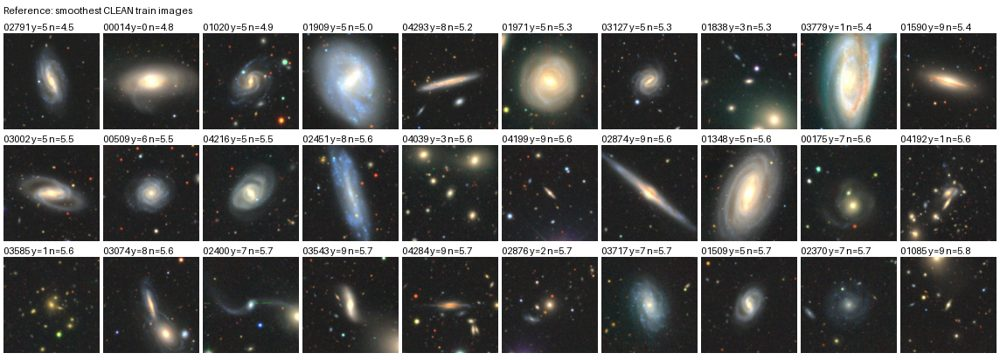

In [17]:
show('04_test/test_smooth_most60.png', width=1000)
show('04_test/clean_train_smoothest30.png', width=1000)

The test images above have a perfectly smooth sky and soft galaxies. Even the smoothest clean train images still show grain.
Checked by eye: **they are blurred**, with no sharp galaxy detail. Fine structures (bars, tight arms: classes 5 vs 6) will be harder to see in part of the test.

## 6. Train ↔ test shift (adversarial validation)

A classifier (gradient boosting on 27 image statistics, 5-fold out-of-fold) tries to tell train from test.
AUC 0.5 = indistinguishable, 1.0 = perfectly separable. Four variants remove the known corruptions step by step.

In [18]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

stat_cols = list(per.columns[per.columns.get_loc('sky_mean') + 1:per.columns.get_loc('dark_flat')])  # same 27 features as the script
feat = [c for c in stat_cols if c != 'skin_blob']
is_tr, is_te = per['split'].eq('train'), per['split'].eq('test')
clean_tr = is_tr & per['category'].eq('clean')
variants = {'all train vs all test': is_tr | is_te,
            'clean train vs all test': clean_tr | is_te,
            'clean train vs untinted test': clean_tr | (is_te & per['tint'].eq('') & ~per['blank']),
            'clean train vs clean test': clean_tr | (is_te & per['category'].eq('clean'))}
res = []
for name, mask in variants.items():
    d = per[mask]; X = d[feat].to_numpy(np.float32); y = d['split'].eq('test').astype(int).to_numpy()
    oof = np.zeros(len(y))
    for a, b in StratifiedKFold(5, shuffle=True, random_state=42).split(X, y):
        oof[b] = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=42).fit(X[a], y[a]).predict_proba(X[b])[:, 1]
    uni = pd.Series({c: roc_auc_score(y, d[c].fillna(d[c].median())) for c in feat}); uni = uni.where(uni >= 0.5, 1 - uni).sort_values(ascending=False)
    res.append({'variant': name, 'n train': int((y == 0).sum()), 'n test': int(y.sum()), 'AUC': round(roc_auc_score(y, oof), 3),
                'most separating features': ', '.join(uni.index[:3])})
display(pd.DataFrame(res).set_index('variant'))

,n train,n test,AUC,most separating features
variant,,,,
all train vs all test,4328,14736,0.971,"chroma_noise, lum_noise, lap_var"
clean train vs all test,2995,14736,0.960,"chroma_noise, lum_noise, lap_var"
clean train vs untinted test,2995,11414,0.952,"chroma_noise, lum_noise, lap_var"
clean train vs clean test,2995,8861,0.942,"chroma_noise, lum_noise, lap_var"


The AUC stays around **0.94 even for clean train vs clean test**. The difference is not limited to the corrupted images:
the whole test is less noisy and less sharp (top features: chroma/luminance noise, Laplacian variance).
This matches the blur seen in §5: the test distribution is shifted as a whole, so train-time augmentation (blur, colour shifts) has to cover it.
Histograms of every statistic (clean train / grainy train / test) are in `05_shift/stats_clean_grainy_test.png`.

## 7. Cleaning proposal

`csv/cleaning_proposal_davide.csv` has one row per train image: `id, label, category, action (keep/drop), reason, dup_group`.
`dup_group` links copies of the same galaxy (near duplicates and grainy→source pairs; value = smallest id of the group), for `StratifiedGroupKFold`.
It is a proposal to compare with the teammate, not the team's frozen `shared/cleaning_ids.csv`.

In [19]:
why = cp['reason'].str.replace(r'train_\d{5}', '<id>', regex=True)
display(cp.assign(reason=why).groupby(['action', 'category', 'reason']).size().rename('images').to_frame())
kept = cp[cp['action'] == 'keep'].groupby('label').size().rename('kept')
display(pd.DataFrame({'name': [CLASS_NAMES[c] for c in range(N_CLASSES)], 'raw': tr.groupby('label').size(), 'kept': kept}).T)
print('total:', cp['action'].value_counts().to_dict())
kg = cp[cp['action'] == 'keep']['dup_group'].value_counts()
print('kept images sharing a dup_group with another kept image:', int(kg[kg > 1].sum()), 'in', int((kg > 1).sum()), 'groups')

images
action category        reason                                                    
drop   alien           alien face pasted on the image                         332
       blank           blank image (flat grey noise)                            1
       broken          broken image (missing-data block + artifact)             1
       grainy          grainy degraded copy of <id> with swapped label        890
                       grainy, no confirmed clean source; label probab...     106
       wrong_label_dup duplicate of <id> with a wrong label (checked b...       3
keep   clean           clean                                                 2995

label,0,1,2,3,4,5,6,7,8,9
name,spaghetti_disturbed,gemelli_merging,gnocchi_round_smooth,ravioli_in_between_smooth,penne_cigar,fusilli_barred_spiral,fusilli_tight_spiral,riccioli_loose_spiral,linguine_edge_on_no_bulge,lasagna_edge_on_bulge
raw,213,345,744,685,83,584,565,477,276,356
kept,182,313,446,343,56,346,309,444,239,317


total: {'keep': 2995, 'drop': 1333}
kept images sharing a dup_group with another kept image: 0 in 0 groups


Decisions taken by eye. Those about single images are applied by the script on every run (`MANUAL` block or a detector):

| date | decision |
|---|---|
| 2026-11-26 | `train_01849` is not grainy (bright halo) |
| 2026-11-26 | `train_00851` is grainy (missed by the detector) |
| 2026-11-26 | wrong-label duplicates dropped: `train_00854`, `train_00284`, `train_00944` |
| 2026-11-26 | 4 uncertain grainy→source pairs are the same galaxy (`train_01992`, `train_00075`, `train_01000`, `train_01894`) |
| 2026-11-26 | the test "smooth" images are blurred |
| 2026-11-26 | no alien hidden in grainy images (all class sheets checked) |
| 2026-11-26 | all 996 grainy images dropped, including the 106 without a confirmed source; no relabelling, no hand review |
| 2026-11-26 | `train_01971` is not an alien (ring spiral, yellow halo); found by the teammate's EDA |
| 2026-11-26 | `train_02179` is broken (missing data + red artifact): new `broken` detector, rule from the teammate's EDA |
| 2026-11-26 | straight-line artifacts are kept: they appear in the test too |

## 8. CNN embeddings

`eda/02_embeddings_davide.py` passes every image through a frozen pretrained CNN (`convnextv2_tiny.fcmae_ft_in22k_in1k`,
the playbook's family D backbone). Each image becomes a 768-number vector (its *embedding*), averaged over the 8 rotations/flips
so that orientation does not matter. Images that look alike to the CNN get close vectors (cosine similarity near 1).
On top of the embeddings:
- **UMAP** squeezes the 768 dimensions into a 2-D map that keeps neighbours close;
- **k-NN** gives each clean train image the majority class of its 10 nearest clean neighbours;
- a **linear probe** (logistic regression, 5-fold out-of-fold) is a free first classifier. Trained on the clean train, it is then
  applied to the grainy images, the aliens and the test;
- an **outlier score** = 1 − mean cosine similarity to the 10 nearest clean train images.

clean train, weighted F1: linear probe (5-fold OOF) 0.576 | k-NN (k=10, leave-one-out) 0.499
eda/outputs/davide/06_embeddings/umap_by_category.png


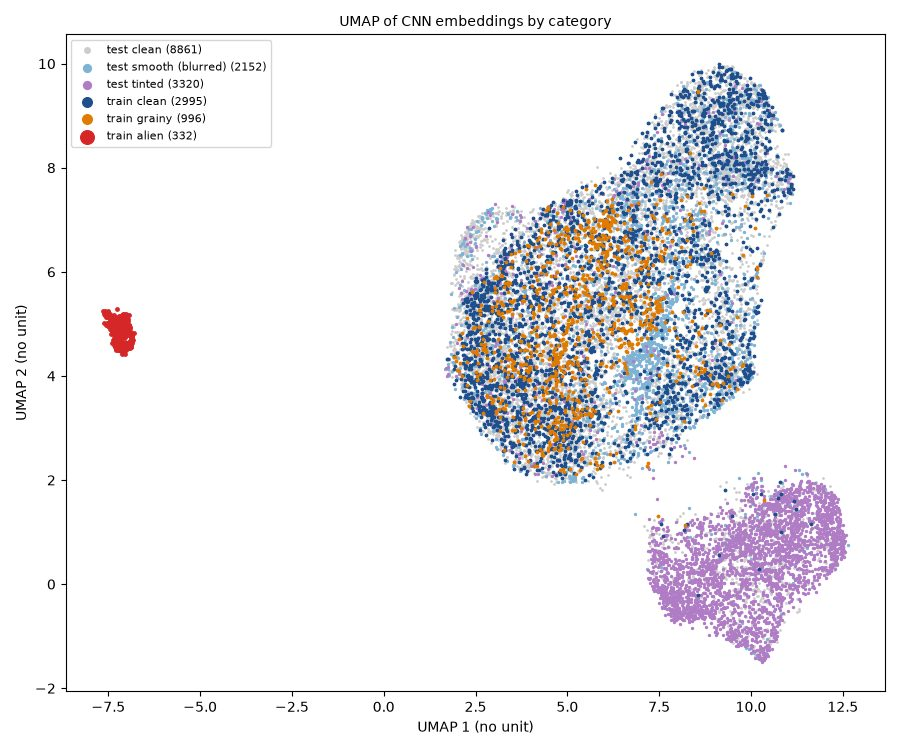

In [20]:
from sklearn.metrics import f1_score
emb = pd.read_csv(OUT / '06_embeddings' / 'embedding_analysis.csv')
ec = emb[(emb['split'] == 'train') & (emb['category'] == 'clean')]
print(f"clean train, weighted F1: linear probe (5-fold OOF) {f1_score(ec['label'], ec['probe_pred'], average='weighted'):.3f} | "
      f"k-NN (k=10, leave-one-out) {f1_score(ec['label'], ec['knn_pred'], average='weighted'):.3f}")
show('06_embeddings/umap_by_category.png', width=900)

The map shows three things at once:
- **Aliens form an island of their own.** Any alien in the test would land there. None does (checked below), which confirms that the test has no aliens.
- **The tinted test forms a separate island, with almost no train image in it.** For the CNN, colour is a strong feature:
  a model trained only on natural colours has to extrapolate on 22.5% of the test.
- **Grainy images mix with the clean ones.** The CNN sees them as normal galaxies, which is why their wrong labels are dangerous.
  The blurred test images form a small dense patch inside the main cloud.

In [21]:
E = np.concatenate([np.load(ROOT / 'eda' / 'outputs' / 'embeddings_cache' / f'emb_convnextv2_tiny_{s}.npy') for s in ('train', 'test')])
assert (pd.read_csv(ROOT / 'eda' / 'outputs' / 'embeddings_cache' / 'emb_convnextv2_tiny_ids.csv')['id'] == emb['id']).all()
E /= np.linalg.norm(E, axis=1, keepdims=True)
al = np.where(emb['category'].eq('alien'))[0]
for name, idx in [('clean train', np.where(emb['category'].eq('clean') & emb['split'].eq('train'))[0]), ('test', np.where(emb['split'].eq('test'))[0])]:
    print(f'{name}: highest cosine similarity to any alien = {(E[idx] @ E[al].T).max():.3f}')
s_al = E[al] @ E[al].T; np.fill_diagonal(s_al, -1)
print(f'aliens: median similarity to the nearest other alien = {np.median(s_al.max(1)):.3f}')

clean train: highest cosine similarity to any alien = 0.543
test: highest cosine similarity to any alien = 0.558
aliens: median similarity to the nearest other alien = 0.975


eda/outputs/davide/06_embeddings/umap_by_class.png


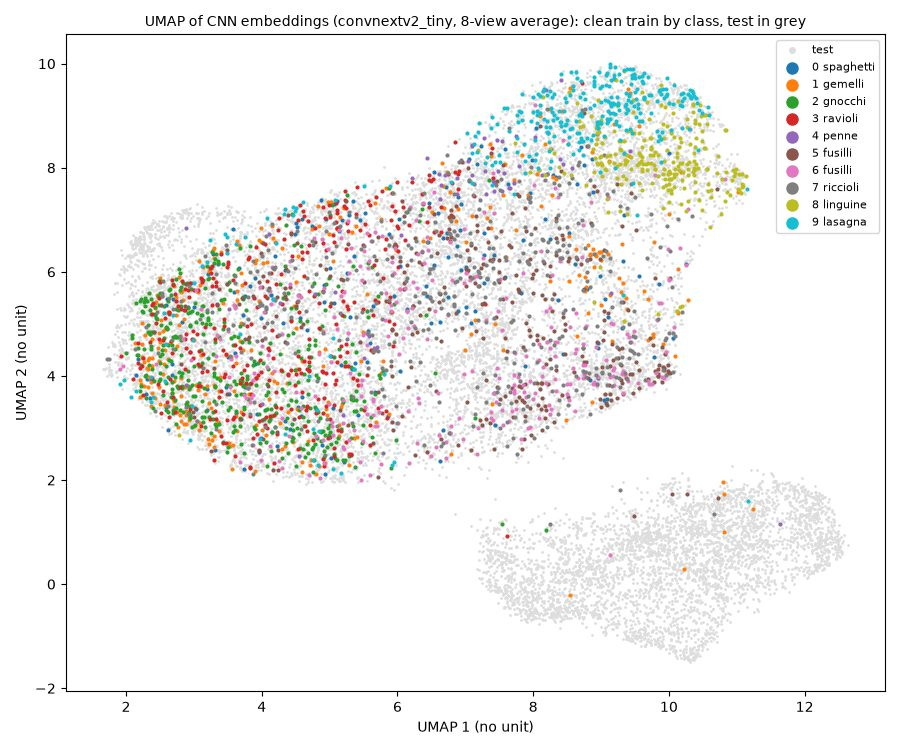

eda/outputs/davide/06_embeddings/confusion_knn_probe.png


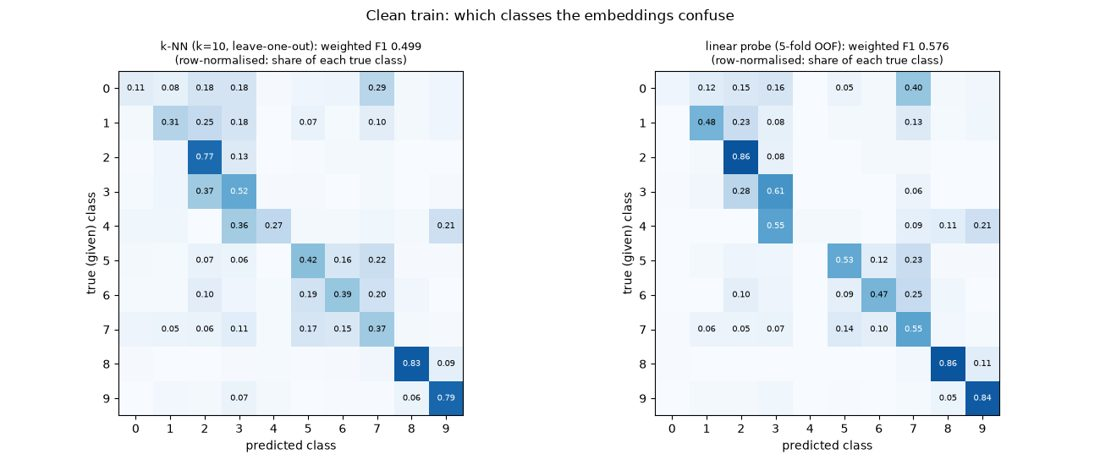

In [22]:
show('06_embeddings/umap_by_class.png', width=900)
show('06_embeddings/confusion_knn_probe.png', width=1100)

**Class overlap.** Frozen features separate the classes only partly (weighted F1 0.58 for the probe). Fine-tuning will do better; this is the family D starting point.
The confusions follow the physics:
- 2 ↔ 3 (round vs in-between smooth);
- 5 / 6 / 7 (the three spiral classes);
- 4 (cigar) → 3 and 9 (elongated);
- 0 (disturbed) → 7;
- 1 (merging) → 2.

Classes 8 and 9 (edge-on) are well separated. The probe almost never predicts classes 0 and 4, so per-class F1 on those will need attention.

**An independent check of the label swap.** The probe never saw a grainy image. If the grainy labels were right, it would mostly predict the given label:

In [23]:
SWAP = {2: 3, 3: 2, 5: 6, 6: 5}
g = emb[emb['category'] == 'grainy'].merge(gm[['id', 'source_status']], on='id')
rows = []
for name, d in [('confirmed copies (890)', g[g['source_status'] == 'confirmed']), ('no confirmed source (106)', g[g['source_status'] != 'confirmed'])]:
    rows.append({'grainy images': name, 'probe = given label': f"{(d['probe_pred'] == d['label']).mean():.0%}",
                 'probe = swapped label': f"{(d['probe_pred'] == d['label'].map(SWAP)).mean():.0%}"})
a = emb[emb['category'] == 'alien']
rows.append({'grainy images': 'for comparison: aliens (332)', 'probe = given label': f"{(a['probe_pred'] == a['label']).mean():.0%}", 'probe = swapped label': '-'})
display(pd.DataFrame(rows).set_index('grainy images'))

,probe = given label,probe = swapped label
grainy images,,
confirmed copies (890),15%,57%
no confirmed source (106),27%,58%
for comparison: aliens (332),12%,-


The probe picks the **swapped** label far more often than the given one: about 4 times for the confirmed copies, and twice for the **106 images without a confirmed source**.
This is independent evidence, from a model that never saw a grainy image, that the 106 are label-swapped too.
The aliens' labels agree with the probe only at chance level (about 12%): their labels carry no information.

**What the probe predicts on the test** (share of predictions, %). Compare each test column with the probe's own out-of-fold predictions on clean train,
not with the true train labels: the probe under-predicts the rare classes 0 and 4 everywhere.

In [24]:
te_e = emb[emb['split'] == 'test']
dist = pd.DataFrame({'clean train: true labels': ec['label'].value_counts(normalize=True),
                     'clean train: probe OOF': ec['probe_pred'].value_counts(normalize=True)})
for c in ['clean', 'smooth', 'tinted']:
    dist[f'test {c}: probe'] = te_e.loc[te_e['category'] == c, 'probe_pred'].value_counts(normalize=True)
dist = (dist.reindex(range(N_CLASSES)).fillna(0) * 100).round(1)
dist.index = [f'{c} {SHORT[c]}' for c in range(N_CLASSES)]
display(dist)

,clean train: true labels,clean train: probe OOF,test clean: probe,test smooth: probe,test tinted: probe
0 spaghetti,6.1,0.6,0.6,0.6,0.1
1 gemelli,10.5,7.7,7.5,8.3,11.0
2 gnocchi,14.9,21.9,18.1,13.4,13.4
3 ravioli,11.5,13.4,13.8,11.2,9.5
4 penne,1.9,0.1,0.4,0.2,0.1
5 fusilli,11.6,9.6,14.0,17.4,29.2
6 fusilli,10.3,8.3,8.7,12.0,0.4
7 riccioli,14.8,18.5,17.4,17.7,17.0
8 linguine,8.0,8.7,9.3,9.3,10.3
9 lasagna,10.6,11.1,10.3,9.9,8.9


- **Clean test** gets almost the same mix as the probe's predictions on clean train. There is no sign of a large class-prior shift.
  A precise prior estimate needs a stronger (fine-tuned) model.
- **Tinted test** is where the frozen model breaks: class 6 almost disappears (0.4% instead of about 8%) and class 5 doubles (29%).
  The colour cast pushes tight spirals into barred spirals. This is the most concrete argument for colour augmentation, and for family D
  it means colour-augmented (or colour-normalised) views when extracting embeddings.

**Adversarial validation on the embeddings** (logistic regression on 50 PCA components, 5-fold): how easily the CNN features separate
clean train from each part of the test.

In [25]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
Zp = PCA(50, random_state=42).fit_transform(E)
ctr = (emb['split'].eq('train') & emb['category'].eq('clean')).to_numpy()
rows = []
for c in ['clean', 'smooth', 'tinted']:
    m = ctr | (emb['split'].eq('test') & emb['category'].eq(c)).to_numpy()
    yy = emb.loc[m, 'split'].eq('test').astype(int).to_numpy()
    p = cross_val_predict(LogisticRegression(max_iter=2000), Zp[m], yy, cv=StratifiedKFold(5, shuffle=True, random_state=42), method='predict_proba')[:, 1]
    rows.append({'clean train vs': f'test {c}', 'n test': int(yy.sum()), 'AUC': round(roc_auc_score(yy, p), 3)})
display(pd.DataFrame(rows).set_index('clean train vs'))

,n test,AUC
clean train vs,,
test clean,8861,0.768
test smooth,2152,0.949
test tinted,3320,0.986


CNN features confirm the picture from the image statistics (§6): tinted test is almost perfectly separable and blurred test strongly.
Clean test is much closer (AUC 0.77 against 0.94 on the image statistics): the CNN is less sensitive to the noise level than the raw statistics, which is good news for training.

**Outliers.** Distance from the clean training set, by category, then the test images farthest from it:

eda/outputs/davide/06_embeddings/outlier_score_by_category.png


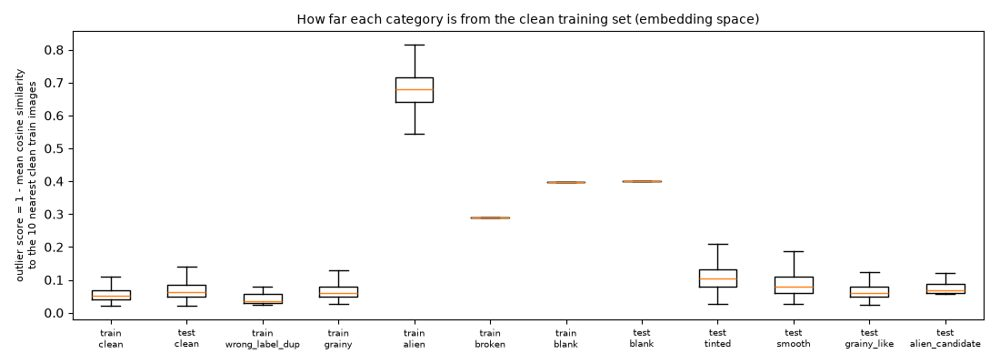

eda/outputs/davide/06_embeddings/test_far_from_train.png


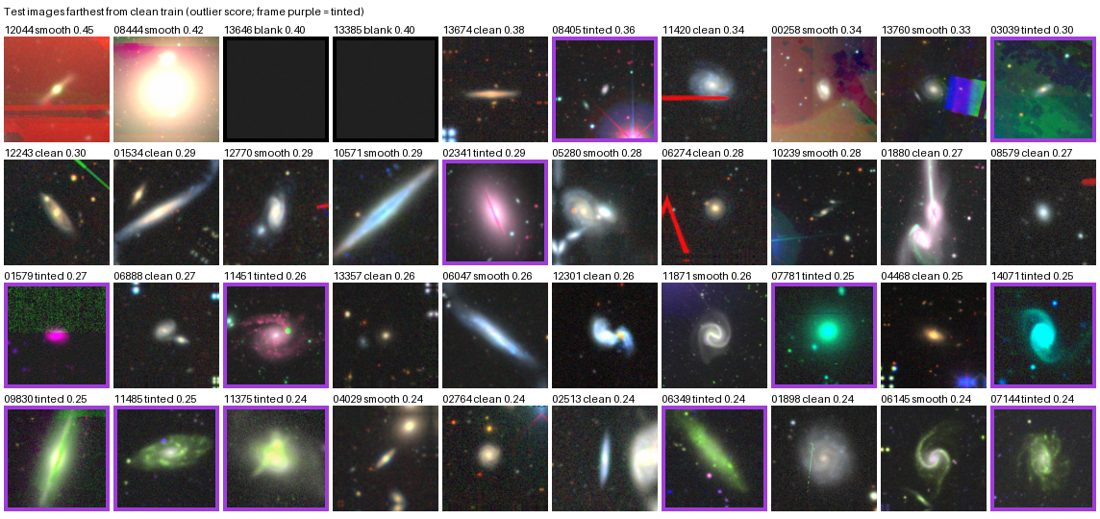

In [26]:
show('06_embeddings/outlier_score_by_category.png', width=1000)
show('06_embeddings/test_far_from_train.png', width=1100)

The test images farthest from train include **partly broken test images**, which the dark-flat rule could not find:
- coloured blocks: `test_12044` (red band), `test_13760` (blue rectangle), `test_01579` (block of green noise);
- a pink blotch: `test_00258`;
- red streaks and lines: `test_11420`, `test_06274`, `test_08579`.

They still have to be predicted (every test image counts in the F1). Augmentations that paste random coloured rectangles or lines (cutout-style)
would make the model robust to them. The rest of the list are tinted images and unusual but genuine galaxies.

**Possible label errors** in the clean train: images whose neighbours mostly belong to one other class.

eda/outputs/davide/06_embeddings/possible_label_errors.png


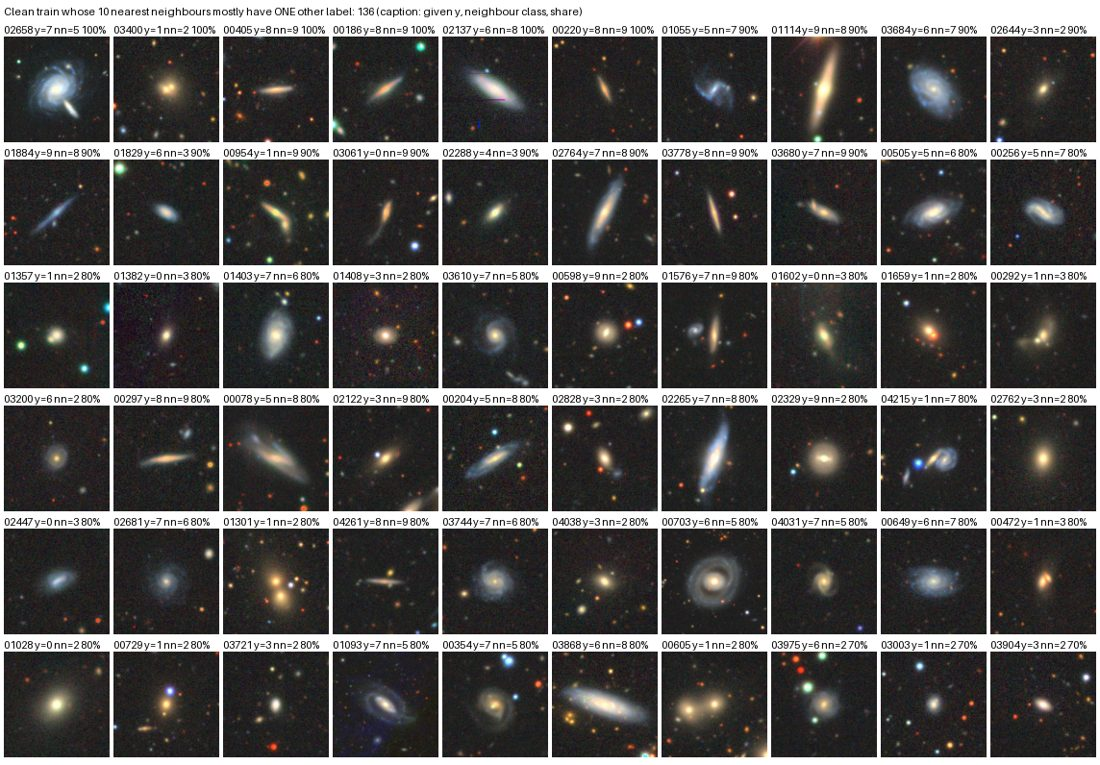

In [27]:
show('06_embeddings/possible_label_errors.png', width=1100)

136 candidates, but most are pairs of adjacent classes that are hard even for the eye:
- 8 ↔ 9: edge-on with or without a bulge;
- 5 / 6 / 7: spiral types;
- 1 → 2: a "merging" image showing a single round galaxy.

With a probe at weighted F1 0.58, the neighbours are not reliable enough to relabel anything, and relabelling by eye would add our own noise. **No action**:
- keep them;
- prefer noise-tolerant training (label smoothing, robust losses);
- re-check the list later with the out-of-fold predictions of a fine-tuned model (confident learning).

## 9. Test distortions measured for augmentation

`eda/03_test_distortions_davide.py` measures the two test distortions, so that the training augmentations reproduce them
instead of using arbitrary strengths.

**Colour cast = HSV hue rotation.** In tinted images the grey sky stays grey, and brightness (V) and saturation (S) are the same as in
untinted images. Only the hue of the coloured parts changes. This is exactly what a hue rotation does
(`torchvision` `adjust_hue` / `ColorJitter(hue=...)`); a per-channel gain would also tint the sky.

eda/outputs/davide/07_test_distortions/tint_undo_examples.png


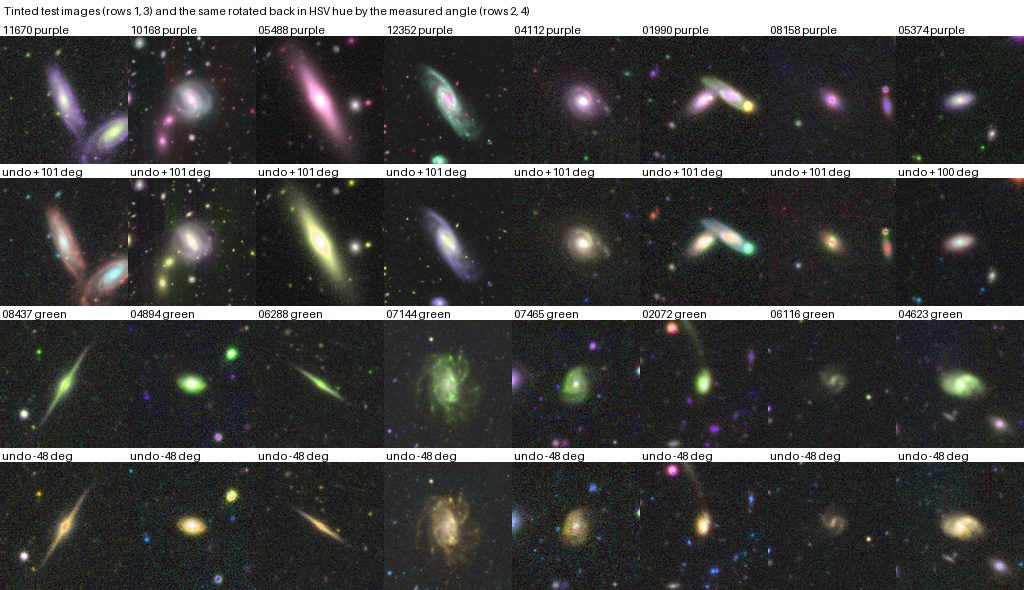

In [28]:
import json
TD = OUT / '07_test_distortions'
td = pd.read_csv(TD / 'test_distortions.csv')
td['tint'] = td['tint'].fillna('')
aug = json.load(open(TD / 'augmentation_params.json'))
show('07_test_distortions/tint_undo_examples.png', width=1100)

Rotating the tinted images back by the measured angle gives natural colours (yellow cores, blue arms): the model of the distortion is right.

**How many test images are rotated, and by how much?** The angle is measured on the galaxy core, which is almost always yellowish,
as the core hue minus the clean-train mean.

eda/outputs/davide/07_test_distortions/hue_shift_hist.png


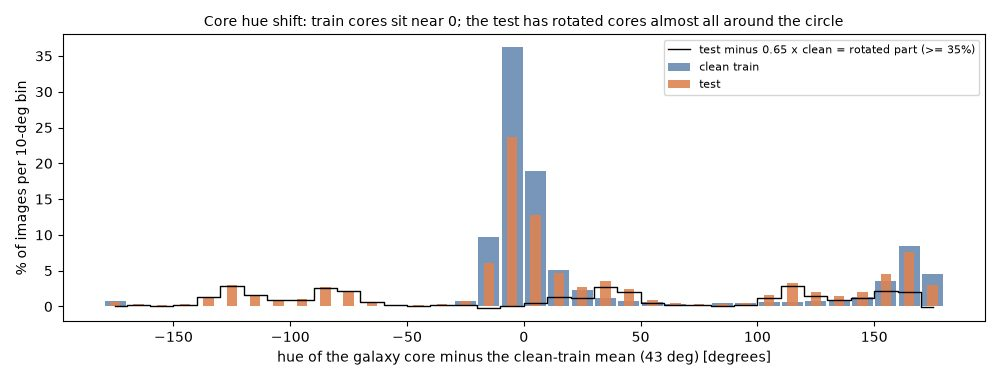

at least 35% of the test is hue-rotated (the core_g detector of §5 found 22.5%)
by band (% of test): {'purple/magenta [-150,-60)': 13.3, 'green/cyan [15,150)': 14.8, '~180 (yellow->blue) [150,180)+[-180,-150)': 4.6}


In [29]:
show('07_test_distortions/hue_shift_hist.png', width=1000)
h = aug['hue_rotation']
print(f"at least {h['measured_min_share_of_test']:.0%} of the test is hue-rotated (the core_g detector of §5 found 22.5%)")
print('by band (% of test):', h['measured_bands_pct_of_test'])

- **At least 35% of the test is hue-rotated**, not 22.5%. Purple/magenta and green/cyan account for about 28%.
  About 5% more are rotated by roughly 180°: yellow cores become blue, which the §5 detector cannot see, because blue cores are also natural.
- The angles cover almost the whole circle. The augmentation should therefore draw the angle **uniformly in [−180°, 180°]**
  (`ColorJitter(hue=0.5)`), with probability about 0.4.

**Blur.** Clean train images are blurred with known Gaussian σ and their sky noise is compared with the test.
The average spectrum gives an independent check.

eda/outputs/davide/07_test_distortions/blur_calibration.png


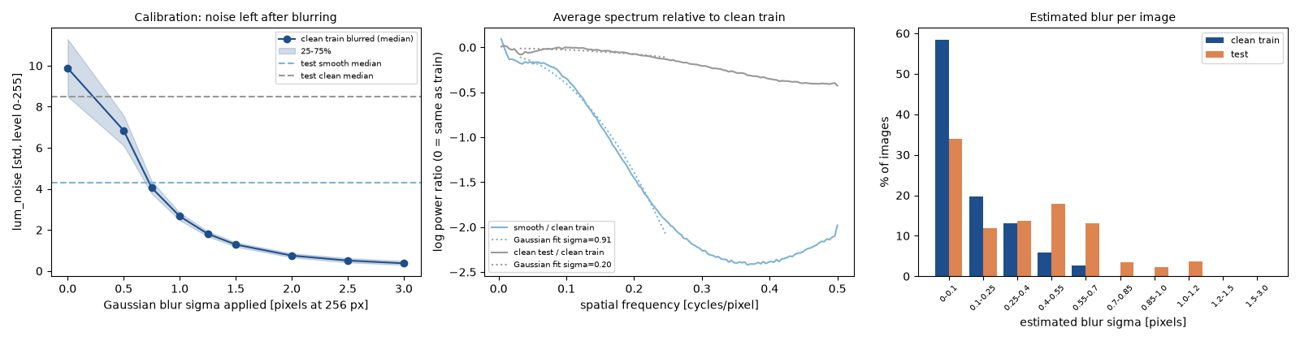

Gaussian sigma fitted on the average spectrum (px at 256): {'smooth_test': 0.91, 'clean_test': 0.2}
test images with estimated sigma >= 0.55 px: 22.6% (clean train: 2.8%); excess of test over train for sigma >= 0.4 px: 31.8%
blurred share among tinted test: 16%, among untinted: 25% (527 images are both)


In [30]:
show('07_test_distortions/blur_calibration.png', width=1300)
b = aug['gaussian_blur']
print('Gaussian sigma fitted on the average spectrum (px at 256):', b['spectrum_fit_sigma_px'])
print(f"test images with estimated sigma >= 0.55 px: {b['measured_share_of_test_sigma_ge_0.55']:.1%} (clean train: {b['same_on_clean_train']:.1%}); "
      f"excess of test over train for sigma >= 0.4 px: {b['measured_excess_share_sigma_ge_0.4']:.1%}")
both = td[(td['tint'] != '') & (td['blur_sigma_est'] >= 0.55)]
print(f"blurred share among tinted test: {(td.loc[td['tint'] != '', 'blur_sigma_est'] >= 0.55).mean():.0%}, among untinted: {(td.loc[td['tint'] == '', 'blur_sigma_est'] >= 0.55).mean():.0%} ({len(both)} images are both)")

- **About 32% of the test has extra blur**, with σ between 0.4 and 1.2 px (the "smooth" images of §5 are the strongest part, σ ≈ 0.9 on the spectrum).
  The clean test is also softened a little (σ ≈ 0.2).
- Blur affects both tinted (16%) and untinted (25%) images: the two distortions were not applied exclusively, so the two augmentations should be **independent**.

Clean train images with the simulated distortions, next to real test images:

eda/outputs/davide/07_test_distortions/simulated_vs_real.png


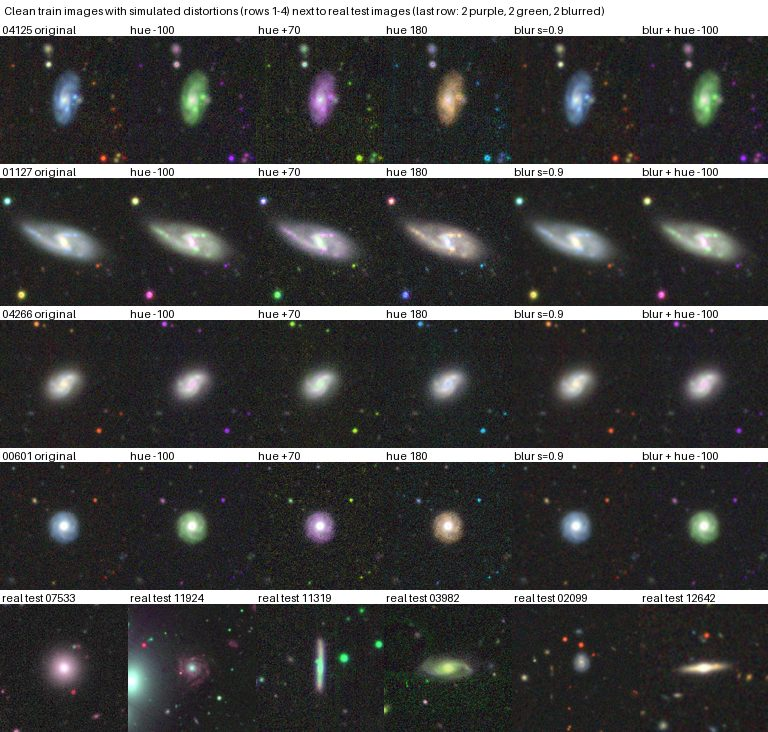

{
 "hue_rotation": {
  "p": 0.4,
  "angle_deg": [
   -180,
   180
  ],
  "torchvision_hue_factor": [
   -0.5,
   0.5
  ]
 },
 "gaussian_blur": {
  "p": 0.35,
  "sigma_px_at_256": [
   0.4,
   1.2
  ],
  "note": "scale sigma by new_size/256 if images are resized first"
 }
}


In [31]:
show('07_test_distortions/simulated_vs_real.png', width=900)
print(json.dumps({k: v['recommended'] for k, v in aug.items() if isinstance(v, dict)}, indent=1))

**Recommended augmentation** (also in `07_test_distortions/augmentation_params.json`, for the training code):

| distortion | probability | strength | implementation |
|---|---|---|---|
| hue rotation | 0.4 | angle uniform in [−180°, 180°] | `ColorJitter(hue=0.5)` applied with p = 0.4 |
| Gaussian blur | 0.35 | σ uniform in [0.4, 1.2] px at 256 px (scale by size/256 after resizing) | `GaussianBlur(kernel_size=5, sigma=(0.4, 1.2))` with p = 0.35 |

The same two transforms, applied to the validation images, give a **test-like validation set**. It shows locally whether a model
survives the colour cast (the 6 → 5 confusion of §8) before submitting.

## 10. Conclusions for training

1. **Train on the 2,995 clean images**: drop the 996 grainy images (label-swapped copies), the 332 aliens, the 3 wrong-label duplicates, 1 broken and 1 blank image.
2. **Augment towards the test**, not just generically:
   - **D4 rotations/flips + arbitrary rotation**: galaxies have no orientation; use the same for TTA.
   - **Hue rotation**, p ≈ 0.4, angle uniform in [−180°, 180°] (`ColorJitter(hue=0.5)`): at least 35% of the test is hue-rotated (§9).
     This overrides the playbook default "hue jitter off".
   - **Gaussian blur**, p ≈ 0.35, σ in [0.4, 1.2] px at 256 px: about 32% of the test is blurred (§9). Independent of the hue rotation.
     §8 shows why it matters: on tinted test a frozen model turns class 6 into class 5.
   - **Random coloured rectangles and lines** (cutout-style), low weight: some test images are partly broken (§8).
3. **Rare class 4** (56 images): watch its per-class F1. Weighted F1 gives it little weight, so class weights only if nested CV says so.
4. **Validation**: after cleaning, no two kept images share a `dup_group`, so stratified K-fold on the clean set is already leak-free.
   Use `StratifiedGroupKFold` with `groups = dup_group` as soon as grainy or restored images are added back.
   Because of the shift (AUC 0.94), check early that CV tracks the public leaderboard, and also report the score on the
   **test-like validation** (validation images with the §9 hue rotation and blur).
5. **Still to do**:
   - a precise test class prior, from a fine-tuned model (the frozen probe shows no large shift on clean test);
   - re-checking the 136 label-error candidates with the out-of-fold predictions of a fine-tuned model;
   - for family D: embeddings of colour-augmented views, and the second backbone of the playbook (`regnety_160.swag_ft_in1k`).
6. **Comparison with the teammate's EDA** (`an2dl2627-batchsize4/notebooks/01_data_cleaning.ipynb`, 2026-11-26):
   - same 332 aliens (different method: random forest on colour histograms + eye), same 3 wrong-label duplicates, same blank image;
   - from their EDA: `train_02179` broken, `train_01971` not an alien, the group column for CV (all three now applied here);
   - not in their EDA: the 996 grainy label-swapped copies (kept in their clean list), the test tints and blur, the adversarial validation.
     Their thumbnail-correlation groups link only 113 of the 890 grainy→source pairs.